In [1]:
import os
import cv2
import glob
import random
import numpy as np
import datetime as dt
import tensorflow as tf
import mediapipe as mp
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

pre-processing

In [2]:
seed_constant = 27
np.random.seed(seed_constant)
random.seed(seed_constant)
tf.random.set_seed(seed_constant)

image_height = 112
image_width = 112
sequence_length = 20

dataset_dir = "dataset_per_kata"

preprocessing: feature extraction

In [3]:
def load_labels(dataset_dir, selected_peraga=None):
    """
    dataset_dir: direktori utama (misal: "dataset_per_kata")
    selected_peraga: list string peraga yang ingin dimuat, misal ["peraga_1", "peraga_2"] atau ["peraga_3"]
    """
    label_map = {}
    
    # Menelusuri semua subfolder kata (AKU, APA, BAGAIMANA, dll.)
    for class_name in sorted(os.listdir(dataset_dir)):
        class_path = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_path):
            continue
            
        for file_name in sorted(os.listdir(class_path)):
            if file_name.endswith(".mp4"):
                # Contoh nama file: peraga_1_AKU_01.mp4
                parts = file_name.split("_")
                peraga_name = f"{parts[0]}_{parts[1]}" # Mendapatkan "peraga_1"
                label = parts[2]                      # Mendapatkan "AKU"
                
                # Filter berdasarkan peraga yang dipilih (jika ada)
                if selected_peraga is not None and peraga_name not in selected_peraga:
                    continue
                
                # Simpan path relatif/lengkap ke file dan labelnya
                relative_path = os.path.join(class_name, file_name)
                label_map[relative_path] = label

    return label_map


def frames_extraction(video_path):
    all_frames = []
    video_reader = cv2.VideoCapture(video_path)

    while True:
        success, frame = video_reader.read()
        if not success:
            break

        resized_frame = cv2.resize(frame, (image_width, image_height))
        normalized_frame = resized_frame / 255.0
        all_frames.append(normalized_frame)

    video_reader.release()
    total_read = len(all_frames)

    if total_read == 0:
        return []

    if total_read >= sequence_length:
        indicies = np.linspace(0, total_read - 1, sequence_length).astype(int)
        frames_list = [all_frames[i] for i in indicies]
    else:
        frames_list = list(all_frames) + [all_frames[-1]] * (sequence_length - total_read)

    return frames_list


def create_dataset(dir = dataset_dir):
    label_map = load_labels(dir)
    classes_list = sorted(set(label_map.values()))

    classes_to_index = {}

    for i in range(len(classes_list)):
        name = classes_list[i]
        classes_to_index[name] = i

    features = []
    labels = []

    for file_name, label in label_map.items():
        print(f"extracting data: {file_name} (label: {label})")
        video_file_path = os.path.join(dir, file_name)
        frames = frames_extraction(video_file_path)

        if len(frames) == sequence_length:
            features.append(frames)
            labels.append(classes_to_index[label])
        else:
            print(f"skipped {file_name}")

    features = np.asarray(features)
    labels = np.array(labels)

    return features, labels, classes_list

mediapipe

In [4]:
pose_idx = [0, 11, 12, 13, 14, 15, 16] # face, left shoulder, right shoulder, left elbow, right elbow, left wrist, right wrist
pose_dim = len(pose_idx) * 2
hand_dim = 21 * 2 * 2 + 1

base_dim = pose_dim + 2 * hand_dim
landmark_dim = base_dim + 1
left_flag_pos = pose_dim + hand_dim - 1
right_flag_pos = base_dim - 1

tap_prominence = 0.15                   # satuan lebar bahu, tuning di data
tap_rel_prominence = 0.08   # puncak dihitung jika >= 8% dari puncak terbesar (tuning, lihat sel diagnostik)
tap_min_abs = 0.05          # lantai absolut agar noise datar tidak ikut
tap_scale = 4.0                        # supaya nilai fitur kira-kira 0..1

shoulder_vis_threshold = 0.3
max_process_width = 640


def new_holistic():
    return mp.solutions.holistic.Holistic(static_image_mode = False, model_complexity = 1, smooth_landmarks = True, min_detection_confidence = 0.5, min_tracking_confidence = 0.5)


def lm_xy(landmark_list, idx = None, aspect = 1.0):
    pts = landmark_list.landmark
    if idx is not None:
        pts = [pts[i] for i in idx]
    return np.array([[p.x * aspect, p.y] for p in pts], dtype = np.float32)


def hand_vector(hand_landmarks, center, scale, aspect = 1.0):
    if hand_landmarks is None:
        return np.zeros(hand_dim, dtype = np.float32)

    xy = lm_xy(hand_landmarks, aspect = aspect)
    body = (xy - center) / scale
    rel = xy - xy[0]
    extent = np.abs(rel).max()
    if extent > 1e-6:
        rel = rel / extent
    return np.concatenate([body.flatten(), rel.flatten(), [1.0]]).astype(np.float32)


def results_to_vector(results, last_state, aspect = 1.0):
    if results.pose_landmarks is not None:
        lm = results.pose_landmarks.landmark
        if lm[11].visibility > shoulder_vis_threshold and lm[12].visibility > shoulder_vis_threshold:
            pts = lm_xy(results.pose_landmarks, pose_idx, aspect)
            l_shoulder, r_shoulder = pts[1], pts[2]
            scale = float(np.linalg.norm(l_shoulder - r_shoulder))
            if scale > 1e-3:
                center = (l_shoulder + r_shoulder) / 2.0
                pose_vec = ((pts - center) / scale).flatten().astype(np.float32)
                last_state = (center, scale, pose_vec)

    if last_state is None:
        return None, last_state

    center, scale, pose_vec = last_state
    left = hand_vector(results.left_hand_landmarks, center, scale, aspect)
    right = hand_vector(results.right_hand_landmarks, center, scale, aspect)
    
    return np.concatenate([pose_vec, left, right]).astype(np.float32), last_state


def select_indices(vectors, sequence = sequence_length):
    valid = [i for i, v in enumerate(vectors) if v is not None]
    if not valid:
        return None

    # tinggi tangan tertinggi per frame (y lebih kecil = lebih tinggi)
    # pose_vec: index 10,11 = wrist kiri (x,y), 12,13 = wrist kanan (x,y)
    h = np.array([min(vectors[i][11], vectors[i][13]) for i in valid])

    k = max(3, len(h) // 10)
    rest = max(np.median(h[:k]), np.median(h[-k:]))   # posisi tangan istirahat
    top = h.min()                                     # posisi tertinggi

    if rest - top > 0.3:                              # ada gerakan terangkat yang jelas
        thr = rest - 0.35 * (rest - top)
        raised = [valid[j] for j in range(len(valid)) if h[j] < thr]
        span = raised
        pad = 2                                       # sisakan sedikit awal/akhir gerakan
        start = max(valid[0], span[0] - pad)
        end = min(valid[-1], span[-1] + pad)
    else:
        # fallback: cara lama (berdasarkan deteksi tangan)
        active = [i for i in valid
                  if vectors[i][left_flag_pos] == 1.0 or vectors[i][right_flag_pos] == 1.0]
        span = active if active else valid
        start, end = span[0], span[-1]

    return np.linspace(start, end, sequence).round().astype(int).tolist()
    

def forward_fill(vectors, indices):
    picked = []

    for i in indices:
        v = vectors[i]

        if v is None:
            j = i

            while j >= 0 and vectors[j] is None:
                j -= 1

            if j < 0:
                j = i

                while j < len(vectors) and vectors[j] is None:
                    j += 1

            v = vectors[j]
        picked.append(v)
    return np.stack(picked)


def count_taps(vectors, start, end):
    seg = forward_fill(vectors, list(range(start, end + 1)))
    y = seg[:, [11, 13]].mean(axis=1)
    if len(y) < 7:
        return 0
    y = savgol_filter(y, 7, 2)
    peaks, props = find_peaks(-y, prominence=tap_min_abs, distance=3)
    if len(peaks) == 0:
        return 0
    proms = props["prominences"]
    return int((proms >= tap_rel_prominence * proms.max()).sum())


def landmark_sequence(vectors, indices):
    seq = forward_fill(vectors, indices)
    taps = count_taps(vectors, indices[0], indices[-1]) / tap_scale
    return np.hstack([seq, np.full((len(seq), 1), taps, np.float32)])


def process_frame_live(frame, holistic, last_state):
    height, width = frame.shape[:2]
    proc = frame

    if width > max_process_width:
        proc = cv2.resize(frame, (max_process_width, int(height * max_process_width / width)))

    results = holistic.process(cv2.cvtColor(proc, cv2.COLOR_BGR2RGB))
    vector, last_state = results_to_vector(results, last_state)
    small = cv2.resize(frame, (image_width, image_height)) / 255.0

    return small.astype(np.float32), vector, last_state, results


def read_and_detect(video_path, keep_full_frames = False):
    small_frames, vectors, raw = [], [], []
    full_frames = []
    cap = cv2.VideoCapture(video_path)
    last_state = None

    with new_holistic() as holistic:
        while True:
            ok, frame = cap.read()

            if not ok:
                break

            small, vector, last_state, results = process_frame_live(frame, holistic, last_state)
            vectors.append(vector)
            small_frames.append(small)

            if keep_full_frames: # kemungkinan bisa dihapus
                height, width = frame.shape[:2]
                proc = frame

                if width > max_process_width:
                    proc = cv2.resize(frame, (max_process_width, int(height * max_process_width / width)))

                full_frames.append(proc)
                raw.append(results)

    cap.release()
    return small_frames, vectors, full_frames, raw


def landmarks_extraction(video_path, sequence = sequence_length):
    small_frames, vectors, _, _ = read_and_detect(video_path)

    if not small_frames:
        return None, None

    indices = select_indices(vectors, sequence)

    if indices is None:
        return None, None

    landmark_seq = landmark_sequence(vectors, indices)
    frame_seq = np.stack([small_frames[i] for i in indices]).astype(np.float32)

    return frame_seq, landmark_seq


def create_dataset_pose(dir = dataset_dir, selected_peraga = None, cache_path = "pose_cache.npz", force_recompute = False):
    # Tambahkan parameter selected_peraga ke load_labels
    label_map = load_labels(dir, selected_peraga=selected_peraga)

    classes_list = sorted(set(label_map.values()))

    # Jika ingin pakai cache per set (train/test), buat nama cache dinamis
    if selected_peraga is not None:
        cache_path = f"pose_cache_{'_'.join(selected_peraga)}.npz"

    if os.path.exists(cache_path) and not force_recompute:
        data = np.load(cache_path, allow_pickle = True)
        if list(data["classes"]) == classes_list and data["landmarks"].shape[-1] == landmark_dim:
            print(f"using cache file: {cache_path}")
            return data["frames"], data["landmarks"], data["labels"], classes_list

    classes_to_index = {name: i for i, name in enumerate(classes_list)}

    frames_all, landmarks_all, labels = [], [], []

    for file_path, label in label_map.items():
        print(f"pose and hands extraction: {file_path} (label: {label})")
        full_video_path = os.path.join(dir, file_path)
        frames, landmarks = landmarks_extraction(full_video_path)

        if frames is None:
            print("skipped (no pose / hands detected)")
            continue

        frames_all.append(frames)
        landmarks_all.append(landmarks)
        labels.append(classes_to_index[label])

    frames_all = np.asarray(frames_all, dtype = np.float32)
    landmarks_all = np.asarray(landmarks_all, dtype = np.float32)
    labels = np.array(labels)

    np.savez_compressed(cache_path, frames = frames_all, landmarks = landmarks_all, labels = labels, classes = np.array(classes_list))
    print(f"saved cache file: {cache_path}")

    return frames_all, landmarks_all, labels, classes_list


def visualize_video_pose(video_path, out_path = "pose_debug.png", sequence = sequence_length, cols = 5):

    mediapipe_draw = mp.solutions.drawing_utils
    mediapipe_holistic = mp.solutions.holistic

    _, vectors, full_frames, raw = read_and_detect(video_path, keep_full_frames = True)
    indices = select_indices(vectors, sequence)

    if indices is None:
        print("no pose / hands detected")
        return

    titles = []

    for t, i in enumerate(indices):
        image = full_frames[i].copy()
        
        r = raw[i]

        mediapipe_draw.draw_landmarks(image, r.pose_landmarks, mediapipe_holistic.POSE_CONNECTIONS)
        mediapipe_draw.draw_landmarks(image, r.left_hand_landmarks, mediapipe_holistic.HAND_CONNECTIONS)
        mediapipe_draw.draw_landmarks(image, r.right_hand_landmarks, mediapipe_holistic.HAND_CONNECTIONS)

        image = cv2.resize(image, (240, 180))

        if r.left_hand_landmarks:
            left_status = "L"
        else:
            left_status = "-"

        if r.right_hand_landmarks:
            right_status = "R"
        else:
            right_status = "-"

        det = left_status + right_status

        text_info = f"t={t} f={i} {det}" #time, frames, detected hands
        cv2.putText(image, text_info, (5, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)

        titles.append(image)

    while len(titles) % cols:
        titles.append(np.zeros_like(titles[0]))

    rows = [np.hstack(titles[k:k + cols]) for k in range(0, len(titles), cols)]
    cv2.imwrite(out_path, np.vstack(rows))

    print(f"saved debug image: {out_path}")


def vgg_preprocessing(x):
    return preprocess_input(x * 255.0)

models (cnn+lstm)

In [5]:
@tf.keras.utils.register_keras_serializable(package="bisindo")
class SeqPart(tf.keras.layers.Layer):
    """Ambil kolom pose+tangan (0..seq_dim-1), buang kolom tap."""
    def __init__(self, seq_dim, **kwargs):
        super().__init__(**kwargs)
        self.seq_dim = seq_dim
    def call(self, x):
        return x[:, :, :self.seq_dim]
    def get_config(self):
        c = super().get_config(); c.update({"seq_dim": self.seq_dim}); return c


@tf.keras.utils.register_keras_serializable(package="bisindo")
class TapOneHot(tf.keras.layers.Layer):
    """Baca kolom tap (konstan sepanjang waktu) -> one-hot jumlah tap (0,1,2,3+)."""
    def __init__(self, tap_col, tap_scale, max_count=3, **kwargs):
        super().__init__(**kwargs)
        self.tap_col, self.tap_scale, self.max_count = tap_col, tap_scale, max_count
    def call(self, x):
        count = tf.round(x[:, 0, self.tap_col] * self.tap_scale)
        count = tf.clip_by_value(count, 0.0, float(self.max_count))
        return tf.one_hot(tf.cast(count, tf.int32), self.max_count + 1)
    def get_config(self):
        c = super().get_config()
        c.update({"tap_col": self.tap_col, "tap_scale": self.tap_scale, "max_count": self.max_count})
        return c

fh_clip = 2.0   # batas fitur, satuan lebar bahu

@tf.keras.utils.register_keras_serializable(package="bisindo")
class HandReach(tf.keras.layers.Layer):
    """Titik tertinggi tangan relatif hidung, minimum sepanjang waktu.
    Negatif = di atas hidung (dahi), ~0 = setinggi hidung/pipi, positif = di bawah."""
    def call(self, x):
        nose_y = x[:, :, 1]
        tops = []
        for wrist_col, start in ((11, pose_dim), (13, pose_dim + hand_dim)):
            wrist_y = x[:, :, wrist_col]
            hand_y = tf.reduce_min(x[:, :, start + 1:start + 42:2], axis=-1)
            seen = x[:, :, start + hand_dim - 1] > 0.5   # tangan tak terdeteksi = nol, jangan dibaca sebagai y=0
            tops.append(tf.where(seen, tf.minimum(wrist_y, hand_y), wrist_y))
        reach = tf.minimum(tops[0], tops[1]) - nose_y
        return tf.clip_by_value(tf.reduce_min(reach, axis=1, keepdims=True), -fh_clip, fh_clip)

In [ ]:


def landmark_branch(seq_input, units = 128):
    x = tf.keras.layers.GaussianNoise(0.02)(seq_input)                        # FIX: sebelumnya tertimpa

    # cnn
    x = tf.keras.layers.Conv1D(filters=64, kernel_size=3, padding="same", activation="relu")(x)   # FIX: (x), bukan (landmark_input)
    x = LayerNormalization()(x)
    return Dropout(0.3)(x)


def temporal_head(x, num_classes, tap = None):

    # lstm
    x = tf.keras.layers.LSTM(64, return_sequences=True, dropout=0.2)(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = Dropout(0.4)(x)
    if tap is not None:                                  # late fusion: tap masuk langsung ke Dense
        x = tf.keras.layers.Concatenate()([x, tap])
    x = Dense(64, activation="relu")(x)
    x = Dropout(0.3)(x)

    # softmax
    return Dense(num_classes, activation="softmax")(x)


def create_pose_lstm(num_classes, summary = True):
    landmark_input = tf.keras.layers.Input(shape=(sequence_length, landmark_dim), name="landmarks")
    seq = SeqPart(base_dim)(landmark_input)
    tap = TapOneHot(base_dim, tap_scale)(landmark_input)
    x = landmark_branch(seq)
    out = temporal_head(x, num_classes, tap)

    model = Model(landmark_input, out, name="pose_hand_lstm")
    if summary:
        model.summary()
    return model


def create_fusion(num_classes):
    frame_input = tf.keras.layers.Input(shape = (sequence_length, image_height, image_width, 3), name = "frames")
    landmark_input = tf.keras.layers.Input(shape = (sequence_length, landmark_dim), name = "landmarks")

    vgg = VGG16(weights = "imagenet", include_top = False, input_shape = (image_height, image_width, 3))
    vgg.trainable = False

    f = tf.keras.layers.TimeDistributed(tf.keras.layers.Lambda(vgg_preprocessing))(frame_input)
    f = tf.keras.layers.TimeDistributed(vgg)(f)
    f = tf.keras.layers.TimeDistributed(GlobalAveragePooling2D())(f)
    f = Dropout(0.3)(f)
    f = tf.keras.layers.TimeDistributed(Dense(64, activation = "relu"))(f)

    seq = SeqPart(base_dim)(landmark_input)
    tap = TapOneHot(base_dim, tap_scale)(landmark_input)

    l = landmark_branch(seq)

    x = tf.keras.layers.Concatenate()([f, l])
    out = temporal_head(x, num_classes, tap)

    model = Model([frame_input, landmark_input], out, name = "fusion_vgg16_model")
    model.summary()
    return model


if __name__ == "__main__":
    dataset_dir = "dataset_per_kata"
    
    train_peraga = ["peraga_2", "peraga_3"]
    test_peraga  = ["peraga_1"]

    print(f"--- MEMUAT DATA TRAINING ({train_peraga}) ---")
    x_train_frames, x_train, y_train_raw, classes_list = create_dataset_pose(
        dataset_dir, selected_peraga=train_peraga, cache_path="cache_train.npz"
    )
    
    # Seterusnya proses model training seperti biasa...
    
    print(f"\n--- MEMUAT DATA TESTING ({test_peraga}) ---")
    x_test_frames, x_test, y_test_raw, _ = create_dataset_pose(
        dataset_dir, selected_peraga=test_peraga, cache_path="cache_test.npz"
    )

    num_classes = len(classes_list)
    print(f"\nNumber of classes: {num_classes}")
    print(f"Classes list: {classes_list}")
    print(f"Train landmarks shape: {x_train.shape}")
    print(f"Test landmarks shape: {x_test.shape}")

    # One-hot encoding labels
    y_train = to_categorical(y_train_raw, num_classes=num_classes)
    y_test = to_categorical(y_test_raw, num_classes=num_classes)

    # Buat dan latih model
    model = create_pose_lstm(num_classes)
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3), 
        loss="categorical_crossentropy", 
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss" ,patience=15, mode="min", restore_best_weights=True
    )

    x_tr, x_val, y_tr, y_val = train_test_split(
        x_train, y_train,
        test_size = 0.2,
        stratify = y_train_raw,      # label integer, bukan one-hot
        random_state = seed_constant,
        shuffle = True,
    )

    
    
    history = model.fit(
        x_tr, y_tr,
        validation_data = (x_val, y_val),
        epochs = 300,
        batch_size = 8,
        shuffle = True,
        callbacks = [early_stopping],
    )

    print(" ================================================================ ")
    print("Evaluation on Test")
    model.evaluate(x_test, y_test)

    date = dt.datetime.now().strftime("%d_%m_%Y(%H-%M-%S)")
    model.save(f"model_{date}.h5")

f1-score

In [ ]:
def get_classes_list(dataset_dir = "dataset"):
    label_map = load_labels(dataset_dir)
    return sorted(set(label_map.values()))

def evaluate_peraga_with_metrics(dataset_dir, test_peraga, model_path):
    classes_list = get_classes_list(dataset_dir)
    print(f"Classes list ({len(classes_list)} kelas): {classes_list}")
    
    model = load_model(model_path)
    
    # Mengumpulkan semua video yang hanya berasal dari peraga test yang diinginkan
    video_files = []
    for class_name in sorted(os.listdir(dataset_dir)):
        class_path = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_path):
            continue
        for filename in sorted(os.listdir(class_path)):
            if filename.endswith(".mp4"):
                # Cek apakah nama file diawali dengan peraga yang diuji (misal: peraga_3_...)
                if filename.startswith(test_peraga):
                    video_files.append(os.path.join(class_path, filename))
    
    if not video_files:
        print(f"Tidak ada file video ditemukan untuk peraga: {test_peraga}")
        return

    total_videos = len(video_files)
    metrics = {cls: {"TP": 0, "FP": 0, "FN": 0, "TN": 0} for cls in classes_list}
    
    print(f"\nMemulai pengujian untuk {total_videos} video dari '{test_peraga}'...\n")
    print(" ================================================================ ")

    for video_path in sorted(video_files):
        filename = os.path.basename(video_path)
        parts = filename.split('_')
        true_label = parts[2].upper() # Menyesuaikan format peraga_X_KATA_01.mp4 -> Indeks ke-2 adalah label
        
        if true_label not in classes_list:
            continue
        
        try:
            _, landmarks = landmarks_extraction(video_path)
            if landmarks is None:
                continue
                
            input_tensor = np.expand_dims(landmarks, axis=0)
            
            probability = model.predict(input_tensor, verbose=0)[0]
            predicted_index = int(np.argmax(probability))
            predicted_class = classes_list[predicted_index]
            confidence = float(probability[predicted_index])
            
            # Update matriks One-vs-All
            for cls in classes_list:
                is_actual = (true_label == cls)
                is_predicted = (predicted_class == cls)
                
                if is_actual and is_predicted:
                    metrics[cls]["TP"] += 1
                elif not is_actual and is_predicted:
                    metrics[cls]["FP"] += 1
                elif is_actual and not is_predicted:
                    metrics[cls]["FN"] += 1
                else:
                    metrics[cls]["TN"] += 1
            
            status = "BENAR" if predicted_class == true_label else "SALAH"
            print(f"Video          : {filename}")
            print(f"True Label     : {true_label}")
            print(f"Predicted Class: {predicted_class} ({confidence * 100:.2f}%) -> [{status}]")
            print("-" * 64)
            
        except Exception as e:
            print(f"Error saat memproses {filename}: {str(e)}")

    # Kalkulasi F1-Score, Precision, Recall (Sama seperti sebelumnya)
    print("\n ================================================================ ")
    print("                HASIL METRIK PER KELAS & F1-SCORE                 ")
    print(" ================================================================ ")
    
    f1_scores = []
    for cls in classes_list:
        tp, fp, fn, tn = metrics[cls]["TP"], metrics[cls]["FP"], metrics[cls]["FN"], metrics[cls]["TN"]
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        f1_scores.append(f1)
        
        print(f"Kelas: {cls} | Precision: {precision*100:.2f}% | Recall: {recall*100:.2f}% | F1-Score: {f1:.4f}")

    macro_f1 = sum(f1_scores) / len(f1_scores) if f1_scores else 0.0
    print(" ================================================================ ")
    print(f" Macro-Average F1-Score Keseluruhan ({test_peraga}) : {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")
    print(" ================================================================ ")

if __name__ == "__main__":
    DATASET_DIR = "dataset_per_kata" # Sesuaikan dengan folder dataset Anda
    
    # PERMUTASI PERAGA TESTING: 
    # Ubah ini sesuai peraga yang ingin Anda uji (misal: "peraga_3", "peraga_2", atau "peraga_1")
    target_test_peraga = "peraga_1" 
    
    # Path model hasil training yang ingin diuji
    MODEL_PATH = "model_16_11_2026(13-41-53).h5" # Ganti dengan nama file model .h5 terbaru Anda
    
    # Membuat path direktori testing secara dinamis berdasarkan peraga yang dipilih
    # Asumsi struktur folder per kata: dataset_per_kata/[KATA]/peraga_X_[KATA]_[no].mp4
    # Kita bisa buat fungsi helper atau langsung ambil sampel path foldernya:
    # Atau jika ingin mengecek video berdasarkan nama file yang mengandung peraga tertentu:
    
    print(f"Menjalankan evaluasi F1-Score khusus untuk: {target_test_peraga}")
    evaluate_peraga_with_metrics(DATASET_DIR, target_test_peraga, MODEL_PATH)

cam

In [ ]:
from tensorflow.keras.models import load_model
import mediapipe as mp
import numpy as np
import time
import cv2

camera_index = 0
model_path = "model_09_10_2026(13-26-44).h5"
dataset_dir = "dataset"

countdown = 3.0
capture_window = 2.0
T = sequence_length

result_display = 2.5
confidence_threshold = 0.0
skeleton_overlay = True


def predict(model, frame_seq, landmark_seq):
    frame, landmark = frame_seq[None], landmark_seq[None]
    return model.predict(landmark, verbose = 0)[0]


def reload_model():
    custom = {}
    try:
        # from cnn_lstm import _vgg16_preprocess_from_unit_range
        custom["vgg_preprocessing"] = vgg_preprocessing
    except Exception:
        pass
    try:
        return load_model(model_path, compile=False, custom_objects=custom)
    except Exception:
        # Keras 3 menolak layer Lambda kecuali safe_mode dimatikan.
        return load_model(model_path, compile=False, custom_objects=custom, safe_mode=False)

    # return load_model(model_path, compile = False, custom_objects = custom, safe_mode = False)


def put_text(frame, text, y, scale = 1.0, color = (255, 255, 255), thick = 2):
    cv2.putText(frame, text, (10, y), cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), thick + 3, cv2.LINE_AA)
    cv2.putText(frame, text, (10, y), cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


def draw_skeleton(display, results):
    draw, hol = mp.solutions.drawing_utils, mp.solutions.holistic

    draw.draw_landmarks(display, results.pose_landmarks, hol.POSE_CONNECTIONS)
    draw.draw_landmarks(display, results.left_hand_landmarks, hol.HAND_CONNECTIONS)
    draw.draw_landmarks(display, results.right_hand_landmarks, hol.HAND_CONNECTIONS)


if __name__ == "__main__":
    model = reload_model()
    num_out = model.output_shape[-1]
    classes = None
    
    classes = sorted(set(load_labels(dataset_dir).values()))

    if not classes or len(classes) != num_out:
        classes = [f"class_{i}" for i in range(num_out)]

    print(f"classes ({num_out}): {classes}")

    cap = cv2.VideoCapture(camera_index)

    if not cap.isOpened():
        raise SystemExit(f"camera index {camera_index} not found")

    state_idle, state_countdown, state_recording, state_result = range(4)
    state = state_idle
    state_start = 0.0
    result_text = []

    holistic = new_holistic()
    post_state = None
    rec_frames, rec_vectors = [], []

    print("tekan SPACE untuk merekam, 'Q' untuk keluar")

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            frame = cv2.flip(frame, 1) # mirror-ing
            now = time.time()
            display = frame.copy()

            if state == state_idle:
                put_text(display, "tekan SPASI untuk mulai", 40, 0.8, (0, 255, 0))

            elif state == state_countdown:
                if skeleton_overlay:
                    _, _, _, results = process_frame_live(frame, holistic, post_state)
                    draw_skeleton(display, results)

                remaining = countdown - (now - state_start)

                if remaining <= 0:
                    state, state_start = state_recording, now
                    rec_frames, rec_vectors = [], []
                    post_state = None
                else:
                    put_text(display, f"get ready... {remaining:0.1f}s", 60, 1.4, (0, 255, 255), 3)

            elif state == state_recording:
                small, vec, post_state, results = process_frame_live(frame, holistic, post_state)

                rec_frames.append(small)
                rec_vectors.append(vec)

                if skeleton_overlay:
                    draw_skeleton(display, results)

                elapsed = now - state_start
                remaining = capture_window - elapsed

                cv2.circle(display, (frame.shape[1] - 30, 30), 12, (0, 0, 255), -1)
                put_text(display, f"recording {max(0.0, remaining):0.1f}s", 40, 0.9, (0, 0, 255))

                if remaining <= 0:
                    indices = select_indices(rec_vectors, T)

                    landmark_seq = landmark_sequence(rec_vectors, indices)
                    frame_seq = np.stack([rec_frames[i] for i in indices]).astype(np.float32)
                    probs = predict(model, frame_seq, landmark_seq)
                    order = np.argsort(-probs)[:3]
                    result_text = [f"{classes[i]}: {probs[i]:.1f}%" for i in order]

                    if probs[order[0]] < confidence_threshold:
                        result_text.insert(0, "(low confidence)")

                    state, state_start = state_result, now

            elif state == state_result:
                k = 0

                for line in result_text:
                    y_pos = 40 + (k * 35)

                    if k == 0:
                        scale = 1.1
                        color = (0, 255, 0)
                    else:
                        scale = 0.85
                        color = (255, 255, 255)

                    put_text(display, line, y_pos, scale, color)
                    
                    k = k + 1

                if now - state_start >= result_display:
                    state = state_idle

            cv2.imshow("cam test", display)
            key = cv2.waitKey(1) & 0xFF

            if key == ord('q'):
                break

            if key == ord(' ') and state == state_idle:
                state, state_start = state_countdown, now
    finally:
        holistic.close()
        cap.release()
        cv2.destroyAllWindows()

inspect

In [ ]:
import os
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================== CONFIG ==============================
VIDEO_PATH = "dataset_per_kata/BAGAIMANA/peraga_2_BAGAIMANA_01.mp4"   
MODEL_PATH = None                        
DATASET_DIR_FOR_CLASSES = dataset_dir    
T = sequence_length                      
OUT_PREFIX = None                       
# ====================================================================
 
# Standard MediaPipe hand topology (21 points)
HAND_CONN = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (5, 9), (9, 10),
             (10, 11), (11, 12), (9, 13), (13, 14), (14, 15), (15, 16), (13, 17), (17, 18),
             (18, 19), (19, 20), (0, 17)]
# pose vector order: 0 nose, 1 Lshoulder, 2 Rshoulder, 3 Lelbow, 4 Relbow, 5 Lwrist, 6 Rwrist
POSE_CONN = [(1, 2), (1, 3), (3, 5), (2, 4), (4, 6)]
 
C_POSE, C_LEFT, C_RIGHT = (255, 200, 0), (0, 220, 0), (0, 140, 255)  # BGR
 
 
def _montage(tiles, cols):
    while len(tiles) % cols:
        tiles.append(np.zeros_like(tiles[0]))
        
    return np.vstack([np.hstack(tiles[k:k + cols]) for k in range(0, len(tiles), cols)])
 
 
# ---------------------------------------------------------------- 1. overlay
def save_overlay(full_frames, raw, indices, filled, path, cols=5):    
    draw, hol = mp.solutions.drawing_utils, mp.solutions.holistic
    tiles = []

    for t, i in enumerate(indices):
        img, r = full_frames[i].copy(), raw[i]

        draw.draw_landmarks(img, r.pose_landmarks, hol.POSE_CONNECTIONS)
        draw.draw_landmarks(img, r.left_hand_landmarks, hol.HAND_CONNECTIONS)
        draw.draw_landmarks(img, r.right_hand_landmarks, hol.HAND_CONNECTIONS)

        img = cv2.resize(img, (240, 180))
        flags = ("L" if r.left_hand_landmarks else "-") + ("R" if r.right_hand_landmarks else "-")
        pose = "P" if r.pose_landmarks else "-"
        col = (0, 0, 255) if filled[t] else (0, 255, 0)

        cv2.putText(img, f"t{t} f{i} {pose}{flags}" + (" FILLED" if filled[t] else ""),
                    (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, col, 1)
        tiles.append(img)

    cv2.imwrite(path, _montage(tiles, cols))
 
 
# --------------------------------------------------------- 2. 64x64 frames
def save_frames64(frame_seq, path, cols=5, scale=3):
    tiles = []

    for t, f in enumerate(frame_seq):
        img = (np.clip(f, 0, 1) * 255).astype(np.uint8)
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
        cv2.putText(img, f"t{t}", (3, 12), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)
        tiles.append(img)

    cv2.imwrite(path, _montage(tiles, cols))
 
 
# ------------------------------------------------------ 3. stick figures
def _to_px(xy, w, h, xr=(-3.0, 3.0), yr=(-1.8, 3.6)):
    x = (xy[0] - xr[0]) / (xr[1] - xr[0]) * w
    y = (xy[1] - yr[0]) / (yr[1] - yr[0]) * h

    return int(x), int(y)
 
 
def draw_skeleton(vec, w=160, h=200):
    # Draw 1 landmark vector (body-normalized part) as a stick figure.
    img = np.full((h, w, 3), 30, np.uint8)
    pose = vec[:pose_dim].reshape(7, 2)

    for a, b in POSE_CONN:
        cv2.line(img, _to_px(pose[a], w, h), _to_px(pose[b], w, h), C_POSE, 2)

    cv2.circle(img, _to_px(pose[0], w, h), 5, C_POSE, -1)          # nose

    for k in (1, 2):
        cv2.circle(img, _to_px(pose[k], w, h), 3, (255, 255, 255), -1)  # shoulders
 
    for start, color in ((pose_dim, C_LEFT), (pose_dim + hand_dim, C_RIGHT)):
        hv = vec[start:start + hand_dim]

        if hv[-1] != 1.0:
            continue

        pts = hv[:42].reshape(21, 2)                                # body-normalized

        for a, b in HAND_CONN:
            cv2.line(img, _to_px(pts[a], w, h), _to_px(pts[b], w, h), color, 1)

        for p in pts:
            cv2.circle(img, _to_px(p, w, h), 1, (255, 255, 255), -1)

    return img
 
 
def save_skeleton_montage(lm_seq, path, cols=5):
    tiles = []

    for t, v in enumerate(lm_seq):
        img = draw_skeleton(v)
        lr = ("L" if v[left_flag_pos] == 1 else "-") + ("R" if v[right_flag_pos] == 1 else "-")
        cv2.putText(img, f"t{t} {lr}", (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 255, 0), 1)
        tiles.append(img)

    cv2.imwrite(path, _montage(tiles, cols))
 
 
# --------------------------------------------------------------- 4. heatmap
def save_heatmap(lm_seq, path):
    fig, ax = plt.subplots(figsize=(14, 5))

    im = ax.imshow(lm_seq.T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)

    for x in (pose_dim - 0.5, pose_dim + hand_dim - 0.5):
        ax.axhline(x, color="k", lw=1.5)

    ax.set_yticks([pose_dim / 2, pose_dim + hand_dim / 2, pose_dim + hand_dim * 1.5])
    ax.set_yticklabels(["pose (14)", "left hand (85)", "right hand (85)"])
    ax.set_xlabel("timestep t")
    ax.set_title("Landmark matrix fed to the LSTM (rows of zeros = hand not detected)")

    fig.colorbar(im, ax=ax, fraction=0.02)
    fig.tight_layout()
    fig.savefig(path, dpi=130)

    plt.close(fig)
 
# ------------------------------------------------- 5. prediction + importance
def _model_kind(model):
    shapes = [tuple(i.shape) for i in model.inputs]
    if len(shapes) == 2:
        return "fusion"
    
    return "frames" if len(shapes[0]) == 5 else "landmark"

 
def _predict(model, kind, fr, lm):
    if kind == "fusion":
        return model.predict([fr, lm], verbose=0)
    
    return model.predict(fr if kind == "frames" else lm, verbose=0)
 
 
def occlusion_importance(model, frame_seq, lm_seq, target):

    kind = _model_kind(model)
    T = len(lm_seq)
    frs, lms = [frame_seq.copy()], [lm_seq.copy()]

    for t in range(T):
        f2, l2 = frame_seq.copy(), lm_seq.copy()
        f2[t], l2[t] = frame_seq.mean(0), lm_seq.mean(0)

        frs.append(f2)
        lms.append(l2)

    probs = _predict(model, kind, np.stack(frs), np.stack(lms))

    return probs[0], probs[0][target] - probs[1:, target]
 

def save_importance(probs, classes, importance, path):
    order = np.argsort(-probs)[:5]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))

    a1.barh([classes[i] for i in order][::-1], probs[order][::-1])
    a1.set_title("Top-5 probabilities")
    a1.set_xlim(0, 1)
    a2.bar(range(len(importance)), importance,
           color=["tab:red" if v > 0 else "tab:gray" for v in importance])
    
    a2.set_title("Frame importance (drop in P(pred) when frame is removed)")
    a2.set_xlabel("timestep t")

    fig.tight_layout()
    fig.savefig(path, dpi=130)

    plt.close(fig)
 
 
def main():
    video, model_path = VIDEO_PATH, MODEL_PATH
    prefix = OUT_PREFIX or f"inspect_{os.path.splitext(os.path.basename(video))[0]}"
 
    small, vectors, full, raw = read_and_detect(video, keep_full_frames=True)

    if not small:
        raise SystemExit("Video tidak bisa dibaca.")
    
    indices = select_indices(vectors, T)

    if indices is None:
        raise SystemExit("Pose tubuh tidak terdeteksi sama sekali -> model tidak akan melihat apa pun.")
 
    filled = [vectors[i] is None for i in indices]
    lm_seq = landmark_sequence(vectors, indices)
    frame_seq = np.stack([small[i] for i in indices]).astype(np.float32)
 
    # ---- console report
    n = len(small)

    pose_n = sum(r.pose_landmarks is not None for r in raw)
    lh_n = sum(r.left_hand_landmarks is not None for r in raw)
    rh_n = sum(r.right_hand_landmarks is not None for r in raw)
    active = [i for i, v in enumerate(vectors) if v is not None and
              (v[left_flag_pos] == 1 or v[right_flag_pos] == 1)]
    
    print(f"\nVideo: {video}  ({n} frames)")
    print(f"Pose detected      : {pose_n}/{n} ({100 * pose_n / n:.0f}%)")
    print(f"Left hand detected : {lh_n}/{n} ({100 * lh_n / n:.0f}%)")
    print(f"Right hand detected: {rh_n}/{n} ({100 * rh_n / n:.0f}%)")

    if active:
        print(f"Active span        : frames {active[0]}..{active[-1]}  "
              f"(model ignores the other {n - (active[-1] - active[0] + 1)} idle frames)")
    else:
        print("Active span        : NO hand ever detected -> falling back to pose-only span!")

    print(f"Filled (forward-fill) timesteps: {sum(filled)}/{len(filled)}")
    print(f"\n{'t':>3} {'frame':>5} {'L':>2} {'R':>2} {'fill':>4} | pose: nose(x,y)  Lwrist(x,y)  Rwrist(x,y)")

    for t, (i, v) in enumerate(zip(indices, lm_seq)):
        p = v[:pose_dim].reshape(7, 2)
        print(f"{t:>3} {i:>5} {'Y' if v[left_flag_pos] else '-':>2} "
              f"{'Y' if v[right_flag_pos] else '-':>2} {'*' if filled[t] else '':>4} | "
              f"({p[0, 0]:+.2f},{p[0, 1]:+.2f})  ({p[5, 0]:+.2f},{p[5, 1]:+.2f})  ({p[6, 0]:+.2f},{p[6, 1]:+.2f})")

    # ---- images
    save_overlay(full, raw, indices, filled, f"out/{prefix}_1_overlay.png")
    save_frames64(frame_seq, f"out/{prefix}_2_frames64.png")
    save_skeleton_montage(lm_seq, f"out/{prefix}_3_skeleton.png")
    save_heatmap(lm_seq, f"out/{prefix}_4_heatmap.png")

    print(f"\nSaved: out/{prefix}_1_overlay.png, out/{prefix}_2_frames64.png, out/{prefix}_3_skeleton.png, out/{prefix}_4_heatmap.png")
 
    # ---- optional model analysis
    if model_path:
        custom = {"vgg_preprocessing": vgg_preprocessing}

        try:
            model = load_model(model_path, compile=False, custom_objects=custom)
        except Exception:  # Keras 3 refuses Lambda layers unless safe_mode is off
            model = load_model(model_path, compile=False, custom_objects=custom, safe_mode=False)

        classes = sorted(set(load_labels(DATASET_DIR_FOR_CLASSES).values())) \
            if os.path.isdir(DATASET_DIR_FOR_CLASSES) else None
        n_out = model.output_shape[-1]
        if classes is None or len(classes) != n_out:
            classes = [f"class_{i}" for i in range(n_out)]
 
        kind = _model_kind(model)
        probs = _predict(model, kind, frame_seq[None], lm_seq[None])[0]
        pred = int(np.argmax(probs))

        print(f"\nModel type: {kind}")
        print(f"Prediction: {classes[pred]} ({probs[pred] * 100:.1f}%)")

        for i in np.argsort(-probs)[:5]:
            print(f"  {classes[i]:<15s} {probs[i] * 100:6.2f}%")

        _, imp = occlusion_importance(model, frame_seq, lm_seq, pred)

        save_importance(probs, classes, imp, f"out/{prefix}_5_importance.png")

        top = np.argsort(-imp)[:3]

        print("Most influential timesteps:", ", ".join(f"t{t} (-{imp[t] * 100:.1f}%)" for t in top))
        print(f"Saved: out/{prefix}_5_importance.png")
 
 
if __name__ == "__main__":
    main()

confusion matrix


Total video: 160 | Accuracy: 81.25%

              precision    recall  f1-score   support

         AKU       1.00      0.80      0.89        10
         APA       1.00      0.40      0.57        10
   BAGAIMANA       0.62      1.00      0.77        10
     BELAJAR       1.00      1.00      1.00        10
   BERANGKAT       1.00      1.00      1.00        10
      DATANG       0.91      1.00      0.95        10
         DIA       0.00      0.00      0.00        10
      DIMANA       0.83      1.00      0.91        10
       INGAT       0.91      1.00      0.95        10
        KAMU       1.00      1.00      1.00        10
       KAPAN       0.56      1.00      0.71        10
        KITA       0.83      1.00      0.91        10
       MAKAN       1.00      0.90      0.95        10
     MENGAPA       1.00      0.20      0.33        10
      MEREKA       0.47      0.90      0.62        10
       SIAPA       1.00      0.80      0.89        10

    accuracy                           0.8

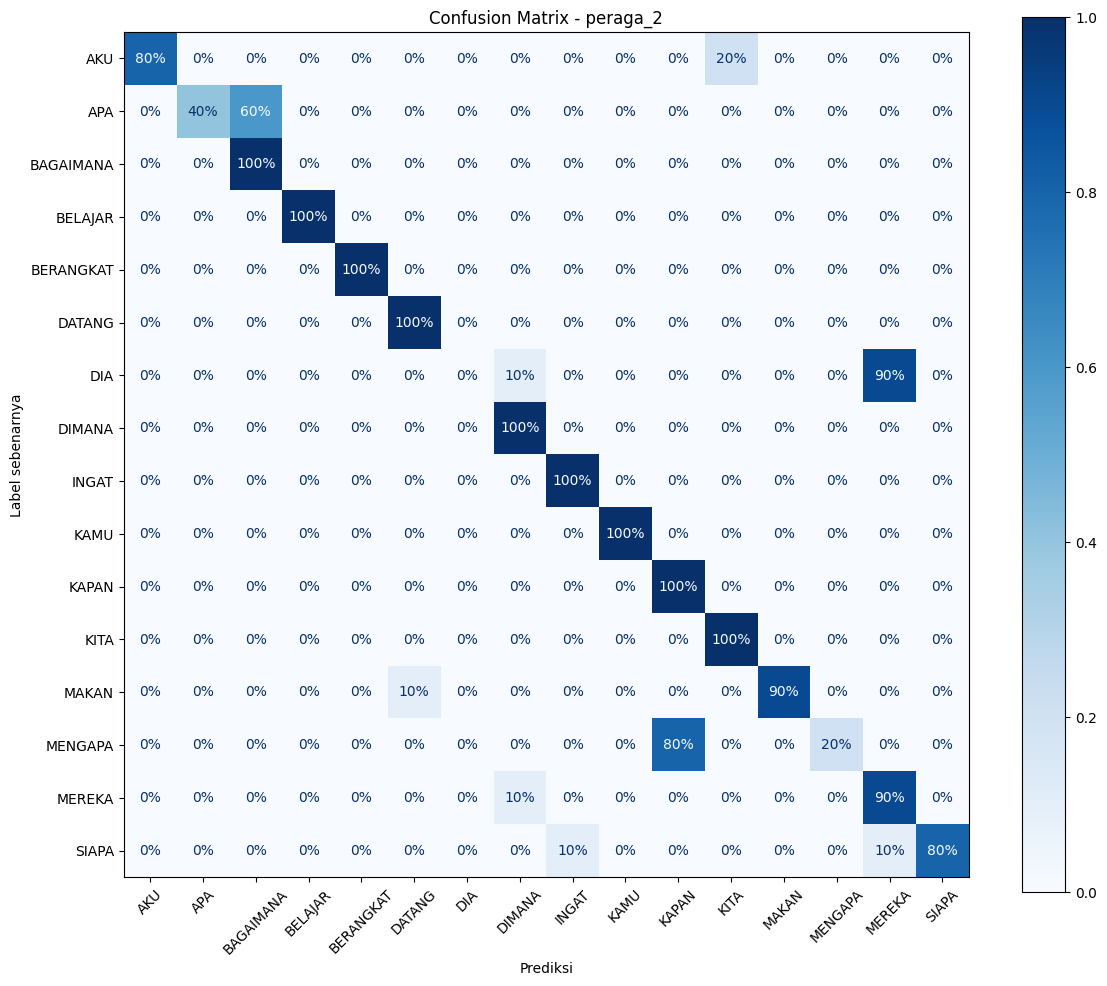


Video salah prediksi:
  peraga_2_AKU_05.mp4: AKU -> KITA
  peraga_2_AKU_08.mp4: AKU -> KITA
  peraga_2_APA_04.mp4: APA -> BAGAIMANA
  peraga_2_APA_05.mp4: APA -> BAGAIMANA
  peraga_2_APA_06.mp4: APA -> BAGAIMANA
  peraga_2_APA_07.mp4: APA -> BAGAIMANA
  peraga_2_APA_08.mp4: APA -> BAGAIMANA
  peraga_2_APA_09.mp4: APA -> BAGAIMANA
  peraga_2_DIA_01.mp4: DIA -> MEREKA
  peraga_2_DIA_02.mp4: DIA -> MEREKA
  peraga_2_DIA_03.mp4: DIA -> MEREKA
  peraga_2_DIA_04.mp4: DIA -> MEREKA
  peraga_2_DIA_05.mp4: DIA -> MEREKA
  peraga_2_DIA_06.mp4: DIA -> DIMANA
  peraga_2_DIA_07.mp4: DIA -> MEREKA
  peraga_2_DIA_08.mp4: DIA -> MEREKA
  peraga_2_DIA_09.mp4: DIA -> MEREKA
  peraga_2_DIA_10.mp4: DIA -> MEREKA
  peraga_2_MAKAN_01.mp4: MAKAN -> DATANG
  peraga_2_MENGAPA_03.mp4: MENGAPA -> KAPAN
  peraga_2_MENGAPA_04.mp4: MENGAPA -> KAPAN
  peraga_2_MENGAPA_05.mp4: MENGAPA -> KAPAN
  peraga_2_MENGAPA_06.mp4: MENGAPA -> KAPAN
  peraga_2_MENGAPA_07.mp4: MENGAPA -> KAPAN
  peraga_2_MENGAPA_08.mp4: MENGAPA -

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ============================== CONFIG ==============================
cm_dataset_dir  = "dataset_per_kata"
cm_test_peraga  = "peraga_2"                          # ganti: "peraga_2" / "peraga_3"
cm_model_path   = "peraga_1_3_train_handreach_77.h5"     # samakan dengan model di cell evaluasi
cm_normalize    = True                                # True = persen per baris (recall), False = jumlah video
cm_save_path    = f"confusion_matrix_{cm_test_peraga}.png"
# ====================================================================


def collect_predictions(dataset_dir, test_peraga, model_path):
    classes_list = sorted(set(load_labels(dataset_dir).values()))
    class_to_index = {c: i for i, c in enumerate(classes_list)}
    model = load_model(model_path)

    y_true, y_pred, names = [], [], []
    for class_name in sorted(os.listdir(dataset_dir)):
        class_path = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_path):
            continue
        for filename in sorted(os.listdir(class_path)):
            if not (filename.endswith(".mp4") and filename.startswith(test_peraga)):
                continue

            true_label = filename.split("_")[2].upper()
            if true_label not in class_to_index:
                continue

            _, landmarks = landmarks_extraction(os.path.join(class_path, filename))
            if landmarks is None:
                print(f"skipped (tidak terdeteksi): {filename}")
                continue

            prob = model.predict(landmarks[None], verbose=0)[0]
            y_true.append(class_to_index[true_label])
            y_pred.append(int(np.argmax(prob)))
            names.append(filename)

    return np.array(y_true), np.array(y_pred), classes_list, names


def plot_confusion_matrix(y_true, y_pred, classes_list, title, normalize=True, save_path=None):
    labels = list(range(len(classes_list)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    if normalize:
        row_sum = cm.sum(axis=1, keepdims=True)
        cm_show = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)
        values_format = ".0%"
    else:
        cm_show = cm
        values_format = "d"

    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_show, display_labels=classes_list)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format=values_format, colorbar=True)
    ax.set_title(title)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label sebenarnya")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150)
        print(f"saved: {save_path}")
    plt.show()
    return cm


y_true, y_pred, classes_list, names = collect_predictions(cm_dataset_dir, cm_test_peraga, cm_model_path)

acc = (y_true == y_pred).mean()
print(f"\nTotal video: {len(y_true)} | Accuracy: {acc * 100:.2f}%\n")
print(classification_report(y_true, y_pred, labels=list(range(len(classes_list))),
                            target_names=classes_list, zero_division=0))

cm = plot_confusion_matrix(
    y_true, y_pred, classes_list,
    title=f"Confusion Matrix - {cm_test_peraga}",
    normalize=cm_normalize,
    save_path=cm_save_path,
)

# daftar video yang salah prediksi
print("\nVideo salah prediksi:")
for n, t, p in zip(names, y_true, y_pred):
    if t != p:
        print(f"  {n}: {classes_list[t]} -> {classes_list[p]}")